# Initial Question

In this project, we aim to analyze various factors and performance statistics of MLB hitters to identify potential links between these variables and the likelihood of a batter hitting a home run

Do barrels correlate with a hitter hitting a home run, and can it be used to predict the likelihood of a batter hitting a home run?

<small>Note: Barrels are when a ball is hit with an exit velocity ≥ 98 mph and a launch angle that results in a minimum expected batting average of .500.</small>

## Data Source

The following data was taken from https://baseballsavant.mlb.com/leaderboard/custom and processed to remove irrelevant columns for future analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
import sklearn.cluster
import sklearn.decomposition

In [3]:
final = pd.read_csv('data/MLB2024BatterStats.csv')

## Linear Regression to analyze Home Runs based on Barrels

Before we try to predict home runs based on barrels, we want to check if the data is highly correlated.

Correlation Coefficient: 0.9546686324121518


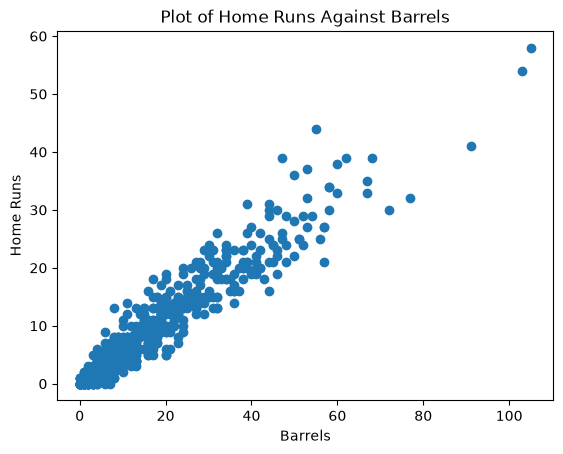

In [4]:
# Replace NaN's with 0s
barrels = final["barrel"].fillna(0)
home_runs = final["home_run"].fillna(0)

# Print the correlation coefficient
print("Correlation Coefficient:", barrels.corr(home_runs))

# Scatterplot of data
plt.scatter(barrels, home_runs)
plt.title("Plot of Home Runs Against Barrels")
plt.xlabel("Barrels")
plt.ylabel("Home Runs")
plt.show()

Looking at the correlation coefficient and the plot, it seems clear that there is indeed a relationship between barrels and home runs.

As such, we will fit a linear regression to the data to see how accurately we can predict home runs based on barrels.

In [5]:
# Prepare data for linear regression and perform linear regression
barrels_regression = final[['barrel']].fillna(0)
lm_home_runs  = LinearRegression().fit(barrels_regression, home_runs)
lm_home_runs.coef_, lm_home_runs.intercept_

(array([0.53943319]), np.float64(0.374542767877756))

In [6]:
# Create new dataframe with predicted data and residuals
home_runs_residual = pd.DataFrame(home_runs)
home_runs_residual["Predicted"] = lm_home_runs.predict(barrels_regression)
home_runs_residual["Residual"] = home_runs_residual.home_run - home_runs_residual.Predicted
# Print the R^2 value
print("R^2 Value:",lm_home_runs.score(barrels_regression, home_runs))
slr_error_magnitude = sum(home_runs_residual.Residual ** 2)
print("Linear Regression MSE:", slr_error_magnitude/len(home_runs_residual.Residual))
home_runs_residual

R^2 Value: 0.9113921977116882
Linear Regression MSE: 7.728512132963054


,home_run,Predicted,Residual
0,21,26.267336,-5.267336
1,54,55.936161,-1.936161
2,37,28.964502,8.035498
3,23,19.794138,3.205862
4,41,49.462963,-8.462963
...,...,...,...
577,0,0.374543,-0.374543
578,0,0.374543,-0.374543
579,0,0.374543,-0.374543
580,0,0.374543,-0.374543


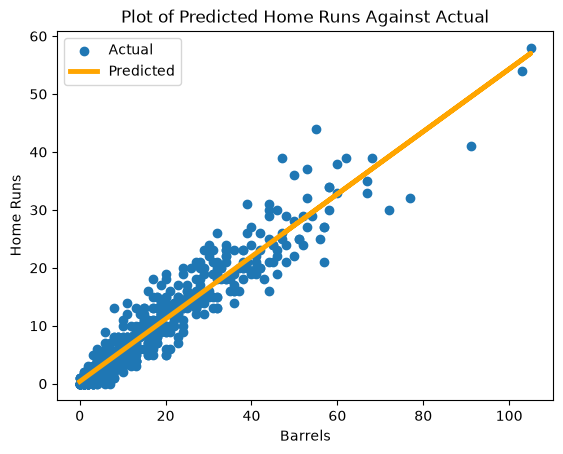

In [7]:
# Plot of predicted data over actual data
plt.scatter(barrels, home_runs, label = "Actual")
plt.plot(barrels, lm_home_runs.predict(barrels_regression), label = "Predicted", c = "orange", lw = 3.5)
plt.title("Plot of Predicted Home Runs Against Actual")
plt.xlabel("Barrels")
plt.ylabel("Home Runs")
plt.legend()
plt.show()

This $R^2$ value means that 91.1% of the variance in the number of home runs can be explained by the number of barrels. The $R^2$ value and the plot of the linear regression line over the actual data show a very strong correlation which makes it clear that we can predict home runs based on barrels.

In order to improve the accuracy of our predictions in the future we can consider fitting a multiple linear regression to more columns to bring more data into the prediction as it is likely that there are more factors that may lead to a higher correlation with home runs.

In [8]:
home_run_coor = final.corr(numeric_only = True)['home_run'].sort_values().fillna(0)
home_run_coor.sort_values(ascending=False).head()

home_run                   1.000000
barrel                     0.954669
b_rbi                      0.932225
pitch_count                0.840323
b_total_swinging_strike    0.836491
Name: home_run, dtype: float64

Looking at the list of correlations between home runs and all the other factors, it is possible that we could fit more data to get a better model for predicting the number of home runs

There is a strong and meaningful relationship between home runs hit and number of barrels. With a high $R^2$ value of 0.911, the model indicates that barrels accounts for approximately 91.1% of the variance in home runs. This suggests that barrel frequency is not only highly correlated with the likelihood of a hitter hitting a home run but also serves as a strong predictor of home run performance.

Two follow up questions we have are

* How does the handedness of a player affect their barrels and home runs
* Can we improve our model using Multiple Linear Regression

## Handedness

Since barrels are the best predictor of home runs, we also wanted to look at how different hitters compare to each other when it comes to barrels and homeruns. The graph looks at handedness of batters and we have three categories. Left handed, right handed, and switch hitters. Switch hitters are ambidextrous.

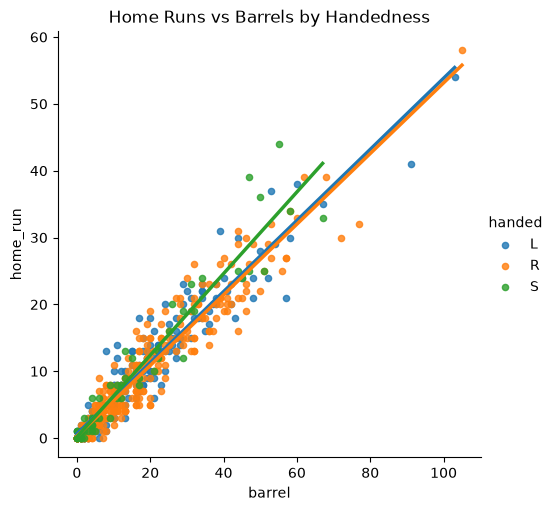

In [9]:
sns.lmplot(
    data=final,
    x="barrel",
    y="home_run",
    hue="handed",
    scatter_kws={"alpha": 0.8, "s": 20},
    line_kws={"linewidth": 2.5},
    ci=None  # Equivalent to se = FALSE in ggplot
)

plt.title("Home Runs vs Barrels by Handedness")
plt.show()

The graph shows that left and right handed batters are predicted to hit about the same number of homeruns from the same amount of barrels; However, switch hitters overperform, hitting more homeruns than both left and right handed players from the same amount of barrels. We can assume this stems from their ability to play to the pitchers weakness by switching which side of the plate they are batting from.

## Multiple Linear Regression

Using the table of correlations related to Home Runs, we will attempt to fit a Multiple Linear Regression to predict Home Runs based on more than just barrels.

To start we will observe the 10 most correlated factors and look at their respective plots against home runs.

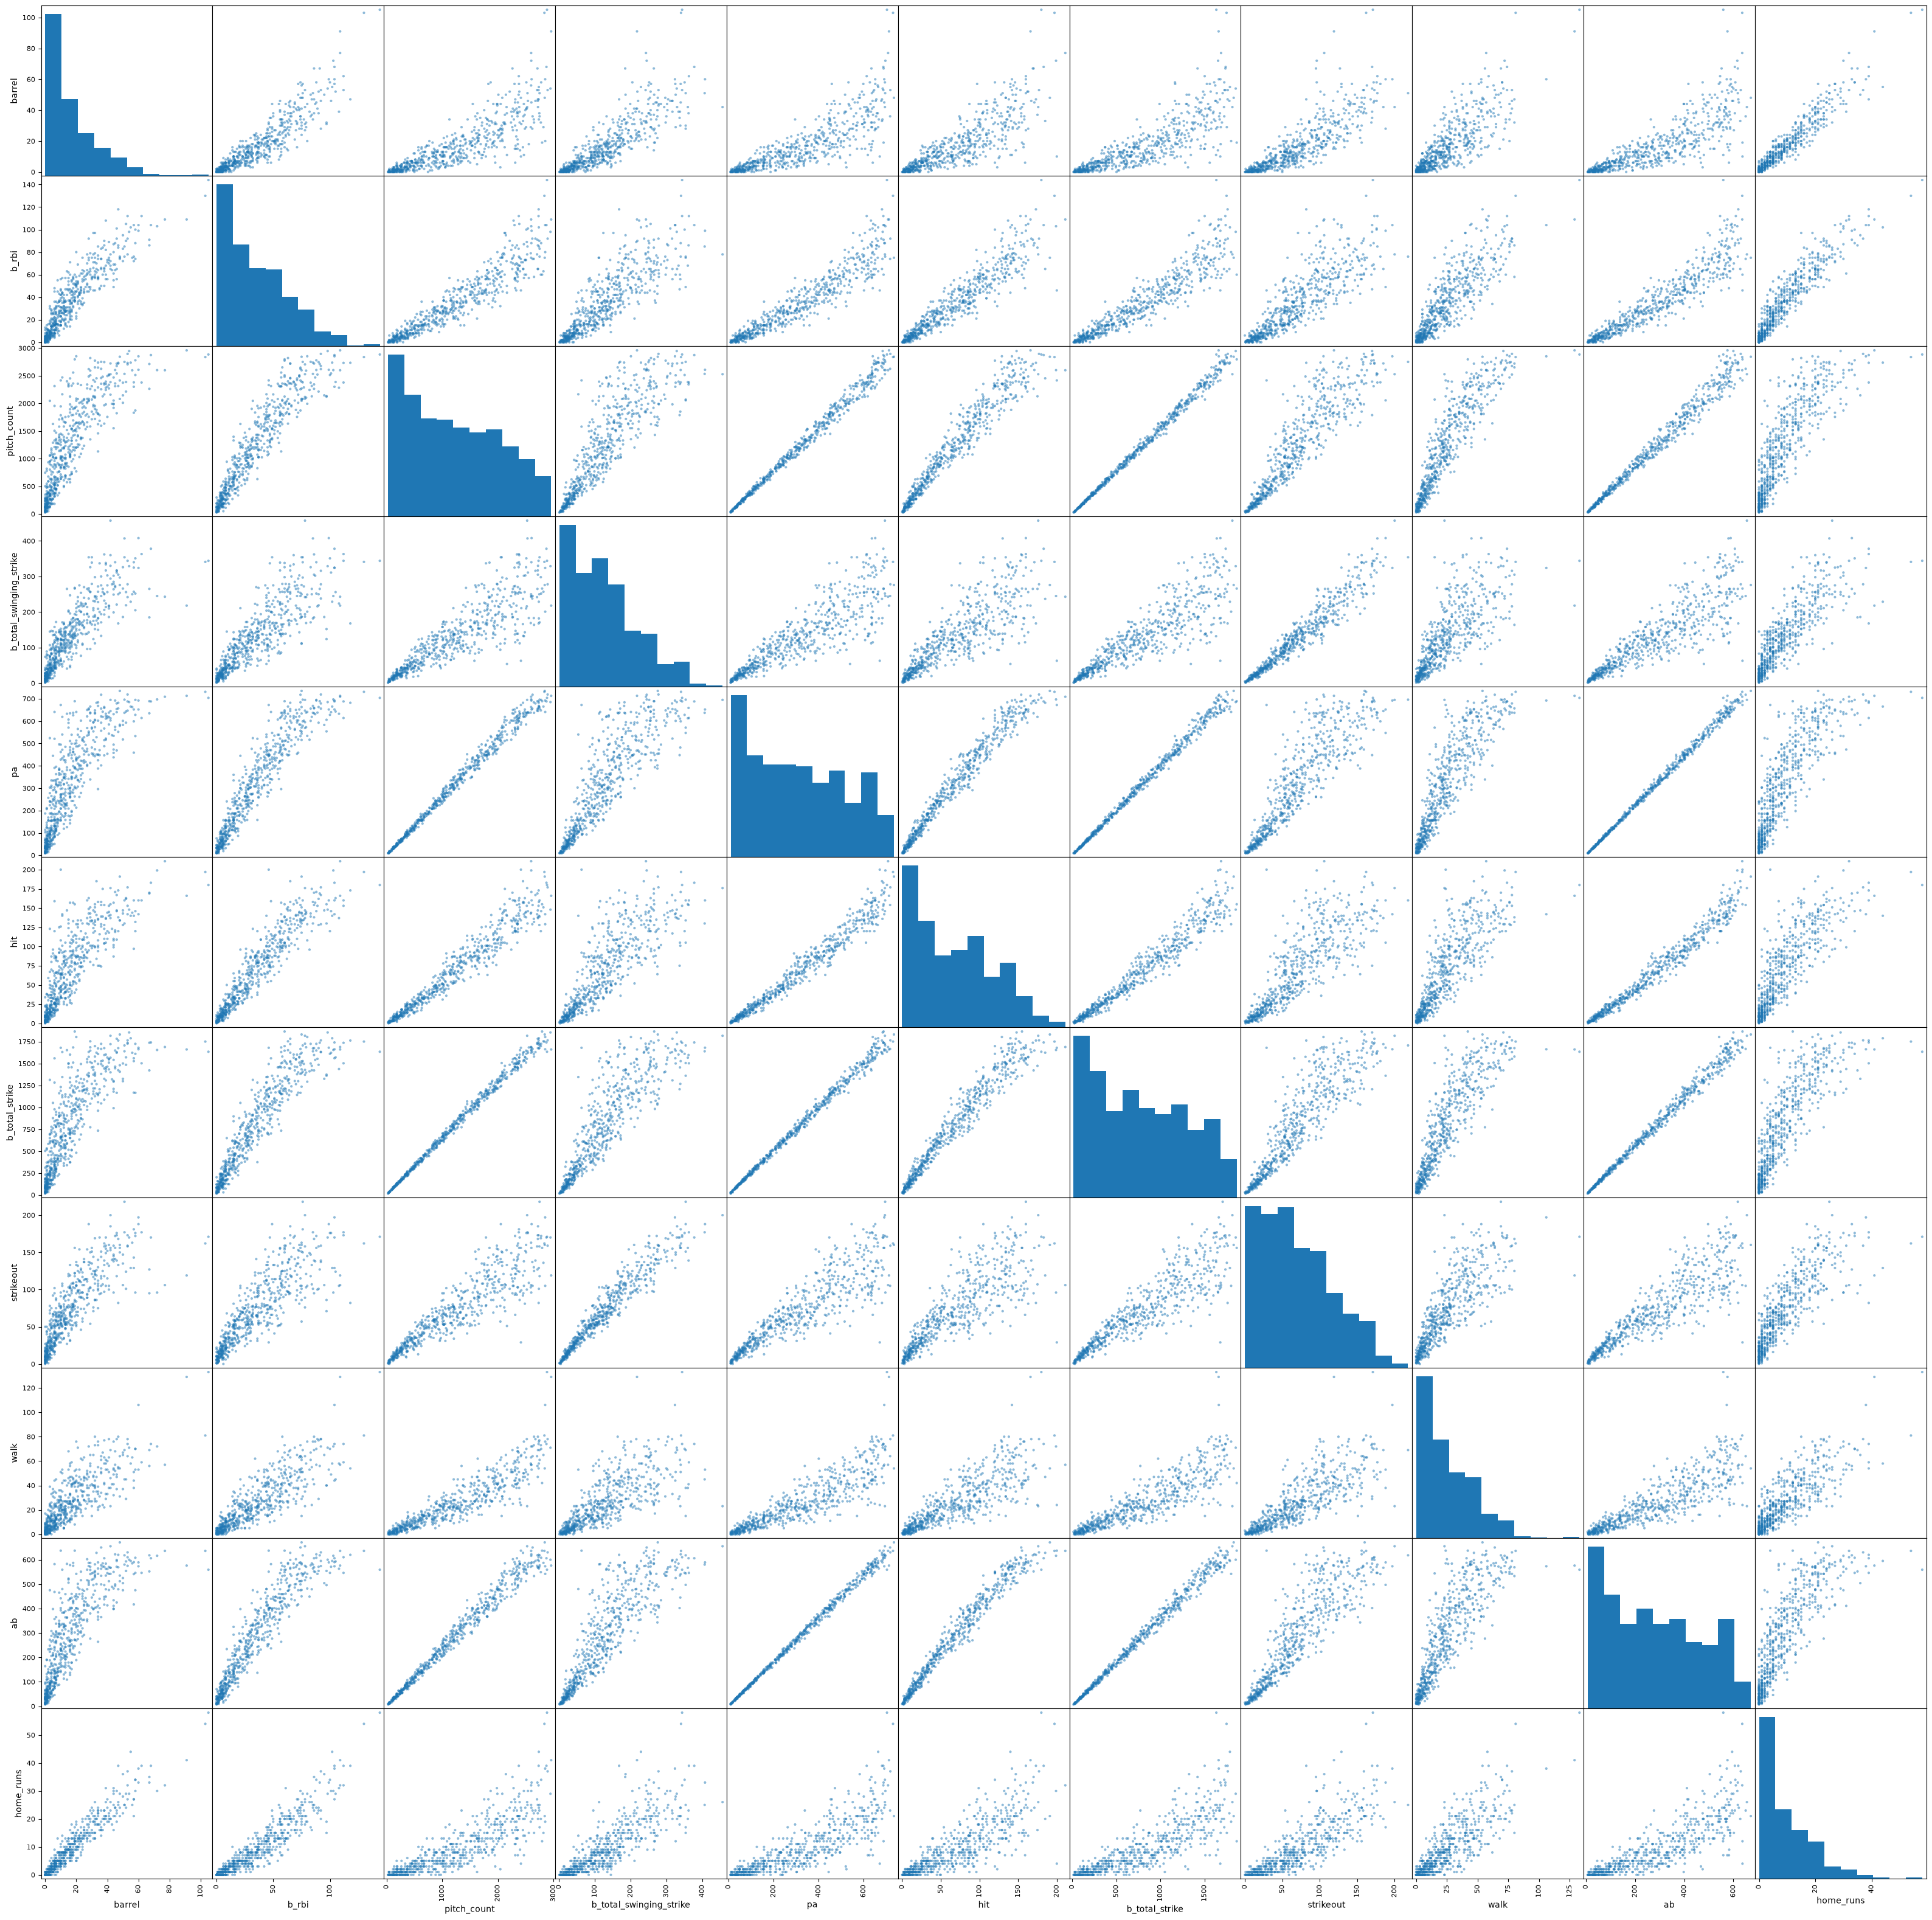

In [10]:
top_ten_corr = pd.DataFrame(home_run_coor.sort_values(ascending = False)[1:11])
top_ten_corr.index

top_ten = final.filter(top_ten_corr.index)
top_ten['home_runs'] = final['home_run']

scatter_matrix_axes = pd.plotting.scatter_matrix(top_ten, figsize = (40,40))
plt.show()

Looking at the plots of home runs against the other 10 variables, it is likely that there is a positive correlation between the variables.

In [11]:
mlr_home_runs = LinearRegression().fit(top_ten.iloc[:,:10], top_ten['home_runs'])

In [12]:
# Create new dataframe with predicted data and residuals
mlr_home_runs_residual = pd.DataFrame(top_ten['home_runs'])
mlr_home_runs_residual["Predicted"] = mlr_home_runs.predict(top_ten.iloc[:,:10])
mlr_home_runs_residual["Residual"] = mlr_home_runs_residual.home_runs - mlr_home_runs_residual.Predicted
# Print the R^2 value
print("R^2 Value:",mlr_home_runs.score(top_ten.iloc[:,:10], home_runs))
mlr_error_magnitude = sum(mlr_home_runs_residual.Residual ** 2)
print("Multiple Linear Regression MSE:", mlr_error_magnitude/len(mlr_home_runs_residual.Residual))
mlr_home_runs_residual

R^2 Value: 0.9424950448554575
Multiple Linear Regression MSE: 5.015672797007366


,home_runs,Predicted,Residual
0,21,22.748976,-1.748976
1,54,50.968295,3.031705
2,37,28.931236,8.068764
3,23,20.278180,2.721820
4,41,45.137282,-4.137282
...,...,...,...
577,0,-0.487169,0.487169
578,0,-0.494259,0.494259
579,0,-0.552289,0.552289
580,0,-0.146370,0.146370


In [13]:
home_run_coor.sort_values(ascending = False)[1:11]

barrel                     0.954669
b_rbi                      0.932225
pitch_count                0.840323
b_total_swinging_strike    0.836491
pa                         0.835263
hit                        0.829709
b_total_strike             0.828563
strikeout                  0.827279
walk                       0.827073
ab                         0.824442
Name: home_run, dtype: float64

Overall, it seems that Multiple Linear Regression has created a better model as our $R^2$ value has increased from 0.92 for Simple Linear Regression to 0.95.

As such, barrel, b_rbi, pitch_count, b_total_swinging_strike, pa, hit, b_total_strike, strikeout, walk and ab seem to be strong predictors of home runs.

## Are younger or older hitters more likely to hit a home run

To answer this question, first we want to separate the players into groups of "younger" and "older" players.

To do this, we will use the average age as the separating line between the players.

27.7766323024055


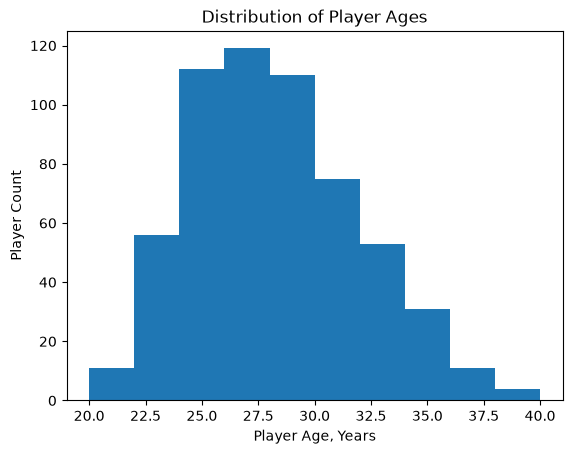

In [14]:
ages = np.array(final["player_age"])
plt.hist(ages, bins = 10)
plt.title("Distribution of Player Ages")
average_age = ages.mean()
print(average_age)
plt.xlabel("Player Age, Years")
plt.ylabel("Player Count")
plt.show()


Based on the distribution of ages and the mean, we will consider players 27 and lower to be "younger" and players 28 and older to be "older"

In [15]:
younger = final[final["player_age"] <= 27]
older = final[final["player_age"] >= 28]
print("Number of 'younger' players: ", len(younger["player_age"]))
print("Number of 'older' players: ", len(older["player_age"]))



Number of 'younger' players:  298
Number of 'older' players:  284


Since the number of 'younger' and 'older' players are similar, 27 appears to be the best age to separate the data.

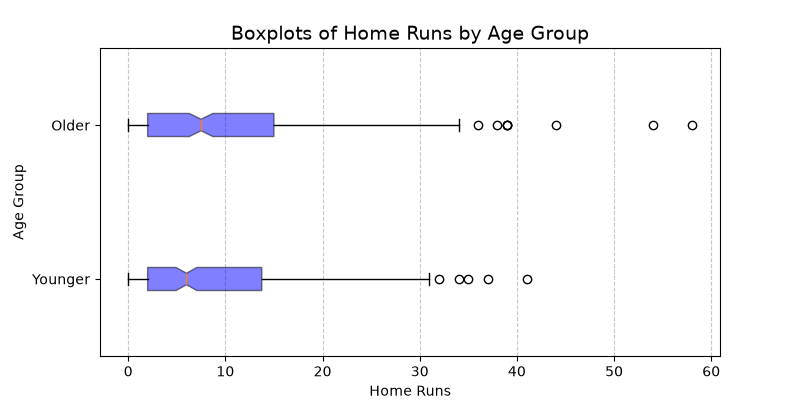

In [54]:
plt.figure(figsize = (8, 4))
plt.boxplot([younger["home_run"], older["home_run"]], tick_labels = ("Younger", "Older"), orientation = 'horizontal', notch = True, patch_artist = True, boxprops = dict(facecolor = "b", alpha = 0.5))
plt.title("Boxplots of Home Runs by Age Group", fontsize = 14)
plt.xlabel("Home Runs")
plt.ylabel("Age Group")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

This boxplot shows that the number of homeruns are very similar for the younger and older age groups. The older age group exhibits a slightly higher average number of home runs than the younger age group.

## MDS

We wanted to look at which players are most similar in their overall hitting profiles. To do this, we created a distance matrix and used MDS to compress the high dimensional data into a 2D space. This allows us to more easily visualize the data and sets us up for questions that would include clustering of some form. This could support other questions such as:
* Are there certain types of players who tend to hit more home runs?
* Do home run hitters cluster together in stat space?
* Do certain teams or positions have better hitters or players that are more likely to hit home runs?

In [17]:
#Creates a copy of the original data table, and changes the index to be the players' name
all_copy = final.copy()
all_copy = all_copy.set_index('player_name').sort_index()

#Creates a table of only numeric data
numeric = all_copy.select_dtypes(include='number')
numeric = numeric.drop(columns='player_id')
numeric = numeric.fillna(0)
numeric = numeric.loc[:, numeric.std() != 0]

#Normalizes the numeric table
normalized = (numeric - numeric.mean()) / numeric.std()
normalized.head()

,player_age,ab,pa,hit,single,double,triple,home_run,strikeout,walk,...,whiff_percent,swing_percent,pull_percent,straightaway_percent,opposite_percent,batted_ball,groundballs_percent,groundballs,linedrives_percent,linedrives
player_name,,,,,,,,,,,,,,,,,,,,,
"Abrams, CJ",-1.286857,1.404738,1.394707,1.291229,1.039024,1.505065,2.662369,1.140232,1.221790,0.686969,...,-0.238118,0.958255,0.871439,-0.602172,-0.486249,1.395638,-0.346107,1.247089,-0.108450,1.206745
"Abreu, José",2.484837,-0.890567,-0.915903,-1.073401,-1.052128,-1.078852,-0.659172,-0.785461,-0.889310,-1.015582,...,0.479195,0.549581,-1.783516,1.353971,0.882540,-0.851974,0.987893,-0.711753,-0.929985,-0.928148
"Abreu, Wilyer",-0.748043,0.643212,0.651668,0.655362,0.208714,1.887868,0.448009,0.605318,1.158457,0.686969,...,0.464849,-0.053701,0.668254,-0.672034,-0.176642,0.454620,-1.105107,0.071784,0.011775,0.396026
"Acuña Jr., Ronald",-0.478637,-0.466901,-0.426936,-0.397793,-0.283322,-0.504648,-0.105582,-0.571495,-0.361535,0.072159,...,0.163577,-0.267768,0.397340,-0.078205,-0.404774,-0.493168,0.930393,-0.288643,-0.048338,-0.495764
"Acuña, Luisangel",-1.556264,-1.287419,-1.299407,-1.113143,-1.175137,-1.078852,-0.105582,-0.678478,-1.353752,-1.157462,...,-0.295504,1.172323,-1.146868,2.104989,-0.584020,-1.210779,0.205893,-1.181875,0.192112,-1.144339


To compute this distance matrix, we decided to use euclidean distance. While euclidean distance is more affected by outliers, we have normalized the data, so no statistic will unfairly dominate. This is also the best to use when evaluating overall similarity in a multidimensional space.

In [18]:
#Euclidean Distance Matrix
import sklearn.metrics.pairwise
distance = sklearn.metrics.pairwise.euclidean_distances(normalized)
distance = pd.DataFrame(distance, index=normalized.index, columns=normalized.index)
distance

player_name,"Abrams, CJ","Abreu, José","Abreu, Wilyer","Acuña Jr., Ronald","Acuña, Luisangel","Adames, Willy","Adams, Jordyn","Adams, Riley","Adell, Jo","Adrianza, Ehire",...,"Wood, James","Wynns, Austin","Yastrzemski, Mike","Yelich, Christian","Yepez, Juan","Yorke, Nick","Yoshida, Masataka","Young, Jacob","Zavala, Seby","d'Arnaud, Travis"
player_name,,,,,,,,,,,,,,,,,,,,,
"Abrams, CJ",0.000000,14.455842,5.128153,9.292608,12.159919,6.254560,12.002229,10.427811,5.642072,14.155591,...,8.513457,14.019474,5.305266,8.342266,8.088388,12.377601,6.511902,8.795183,14.367540,7.112734
"Abreu, José",14.455842,0.000000,13.873405,12.068173,13.084076,17.083293,9.848301,8.384713,12.329835,10.283600,...,14.053987,16.399621,13.674231,14.817188,10.886824,12.279076,12.275635,12.368917,13.202002,10.935924
"Abreu, Wilyer",5.128153,13.873405,0.000000,7.224617,10.548488,6.153843,10.764824,8.535857,3.810558,13.203513,...,7.278858,12.479164,6.008055,7.598803,7.887619,10.676543,6.832516,10.472714,13.420142,5.821920
"Acuña Jr., Ronald",9.292608,12.068173,7.224617,0.000000,8.489486,11.407839,8.111011,5.208212,6.922547,11.766152,...,5.224884,11.825928,9.758449,5.574027,6.628518,7.072999,7.538128,10.666574,12.783514,6.587981
"Acuña, Luisangel",12.159919,13.084076,10.548488,8.489486,0.000000,14.730168,9.438336,7.960734,10.706159,12.794816,...,9.853068,10.464601,12.183085,9.264497,8.289535,8.325872,9.798707,12.809658,14.969233,9.480077
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Yorke, Nick",12.377601,12.279076,10.676543,7.072999,8.325872,14.477393,7.658690,7.643807,10.123247,10.520116,...,8.121466,11.946903,12.440777,9.178349,8.694874,0.000000,9.856917,12.202278,12.693898,8.731542
"Yoshida, Masataka",6.511902,12.275635,6.832516,7.538128,9.798707,8.928591,9.419730,8.313172,7.468701,11.866041,...,7.697559,11.144407,7.870183,6.201642,4.800880,9.856917,0.000000,6.515590,13.871809,5.708788
"Young, Jacob",8.795183,12.368917,10.472714,10.666574,12.809658,12.050875,10.593528,10.681365,10.360747,13.149643,...,9.485150,14.864004,10.684170,9.997031,6.962970,12.202278,6.515590,0.000000,16.383044,9.025389


From the euclidean distance matrix, we are able to use MDS to condense the high dimensional data into 2 dimensions, allowing us to more easily visualize the distance between the points. Or in this case, the players.

In [55]:
#MDS
import sklearn.manifold
mds = sklearn.manifold.MDS(n_components=2, metric='precomputed', init='random', n_init=10, max_iter=100)
table2D = mds.fit_transform(distance)
table2D = pd.DataFrame(table2D, index=normalized.index, columns=['X','Y'])
table2D

,X,Y
player_name,,
"Abrams, CJ",-6.513500,-0.300080
"Abreu, José",9.691591,1.198610
"Abreu, Wilyer",-4.700828,3.259012
"Acuña Jr., Ronald",-0.368496,5.601177
"Acuña, Luisangel",1.946241,8.613658
...,...,...
"Yorke, Nick",3.187528,7.322038
"Yoshida, Masataka",-3.297001,-2.235965
"Young, Jacob",-2.209435,5.718492


This graph plots all players from the two dimensional table. The names are not included in this graph as it would make seeing some of the points more difficult. A graph containing all player names and their associated points can be found below.

<Axes: xlabel='X', ylabel='Y'>

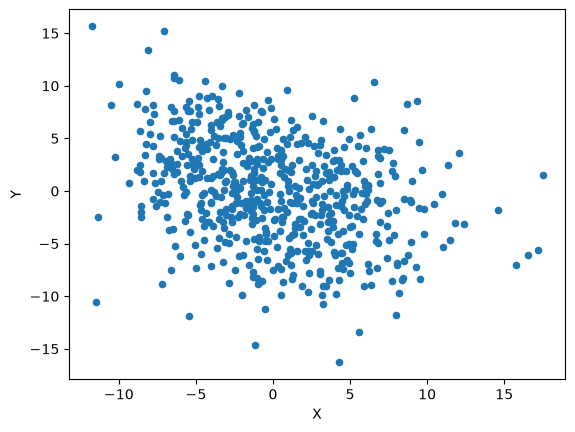

In [20]:
#Plot without player names
mds_plot = table2D.plot.scatter(x='X', y='Y')
mds_plot

This graph includes the player names associated with each point, this does make the visual more difficult to interpret.

<Axes: xlabel='X', ylabel='Y'>

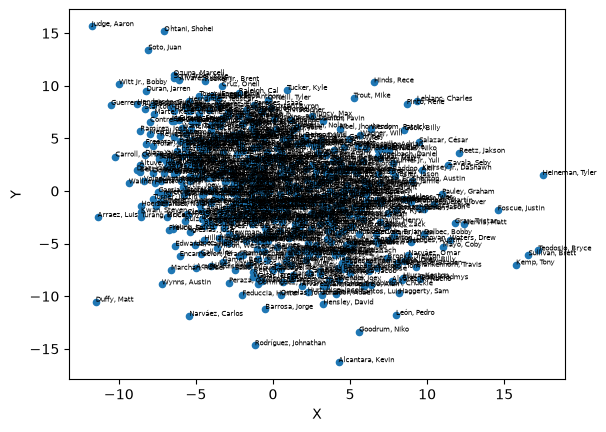

In [21]:
#Plot with player names
mds_plot = table2D.plot.scatter(x='X', y='Y')
for i, r in table2D.iterrows():
    mds_plot.text(r.X, r.Y, i, fontsize=5)
mds_plot

More work would need to be done to answer further questions, but this has a good setup for answering potential questions down the line.

## PCA For K Means

One of the potential questions we want to answer from our MDS analysis is whether we can cluster players in order to determine which performance metrics are associated with hitting a home run.

To do this we will attempt to cluster the players into distinct different clusters and seeing if

* Home run average differs between the clusters
* If they do, what are the factors that differentiate the clusters

Given the large amount of different statistics available, we use PCA to reduce this down to a more manageable size to determine only the most impactful metrics

First, we remove the year, player_id and home_run columns and normalize the data

In [22]:
final_norm = final.select_dtypes(include='number')
final_norm = (final_norm - final_norm.mean())/final_norm.std()
final_norm = final_norm.drop('year', axis = 1)
final_norm = final_norm.drop('player_id', axis = 1)
final_norm = final_norm.drop('home_run', axis = 1)
final_norm = final_norm.set_index(final['player_name'])
final_norm.head()

,player_age,ab,pa,hit,single,double,triple,strikeout,walk,k_percent,...,whiff_percent,swing_percent,pull_percent,straightaway_percent,opposite_percent,batted_ball,groundballs_percent,groundballs,linedrives_percent,linedrives
player_name,,,,,,,,,,,,,,,,,,,,,
"Duran, Jarren",-0.209230,2.101910,2.032281,2.443739,1.961591,3.323377,7.091091,1.897343,1.349072,-0.334586,...,-0.223772,-0.014779,-1.201051,0.620417,0.866245,2.052319,0.355393,2.359711,0.472636,2.206632
"Ohtani, Shohei",0.329583,1.914210,2.013106,2.562964,1.654069,2.366371,3.215959,1.939565,2.625985,-0.280147,...,0.493541,-0.209386,0.654708,-0.672034,-0.160347,1.808602,-0.852107,1.309772,0.733122,2.125560
"Henderson, Gunnar",-1.286857,1.882033,1.955581,2.165547,1.777078,1.696466,3.215959,1.876232,2.484106,-0.293757,...,-0.281157,-0.812668,-0.293490,0.620417,-0.225528,1.781523,0.424393,2.108979,0.272261,1.801272
"Semien, Marcus",1.407210,1.989290,1.950787,1.708517,1.777078,1.313664,0.448009,0.736237,1.822003,-1.314492,...,-0.883701,0.316052,0.979805,-0.479913,-0.730676,2.262187,-0.472607,1.967943,-0.148525,1.963416
"Soto, Juan",-0.748043,1.592438,1.926818,1.946967,1.408051,1.696466,1.555189,1.031791,4.896053,-1.028686,...,-0.697199,-2.174917,0.478614,-0.113136,-0.469954,1.686744,0.113893,1.811235,-0.088413,1.476985


Next we use PCA to reduce the dimension of the normalized data

In [23]:
import sklearn.decomposition
final_pca = sklearn.decomposition.PCA()
final_PCA = final_pca.fit_transform(final_norm)
finalPCA = pd.DataFrame(final_PCA, index = final_norm.index)
finalPCA.head()

,0,1,2,3,4,5,6,7,8,9,...,42,43,44,45,46,47,48,49,50,51
player_name,,,,,,,,,,,,,,,,,,,,,
"Duran, Jarren",9.396925,-2.332587,-0.457953,-2.582106,-1.299047,0.791456,1.738029,0.123174,0.519806,0.861888,...,0.021737,0.034138,-0.000194,-0.011789,0.001337,6.655632e-04,-0.000656,0.001745,-2.889255e-14,5.596939e-15
"Ohtani, Shohei",14.439790,4.423543,-0.324542,-0.811198,0.149489,-0.615582,0.398228,-0.440626,0.272761,-0.173064,...,-0.005928,0.056798,-0.008365,-0.001220,0.016681,-1.643976e-03,0.003567,-0.005975,1.153677e-13,-1.292823e-14
"Henderson, Gunnar",10.206569,0.446501,0.054089,-2.756044,0.719800,0.501389,0.936748,-0.427300,0.850831,0.279568,...,0.022698,0.137719,0.016183,0.008226,0.003205,5.024487e-07,0.001066,0.008457,1.212790e-13,-1.330054e-14
"Semien, Marcus",5.482087,-3.872734,-2.072540,1.449133,0.941151,-0.942616,-1.076034,0.325080,-0.691359,-0.444747,...,0.034907,-0.021116,0.015808,-0.003903,-0.025805,-4.480020e-03,-0.001607,0.000662,-3.987303e-14,5.276676e-14
"Soto, Juan",12.945710,3.052238,1.613678,-1.059035,3.998056,-0.366957,0.687994,-1.726946,1.240083,-0.809438,...,0.054028,-0.042462,-0.009655,-0.005409,-0.004972,1.793198e-03,0.000079,0.002685,-1.568988e-13,6.002656e-14


Below is a plot of the first 2 Principal Components

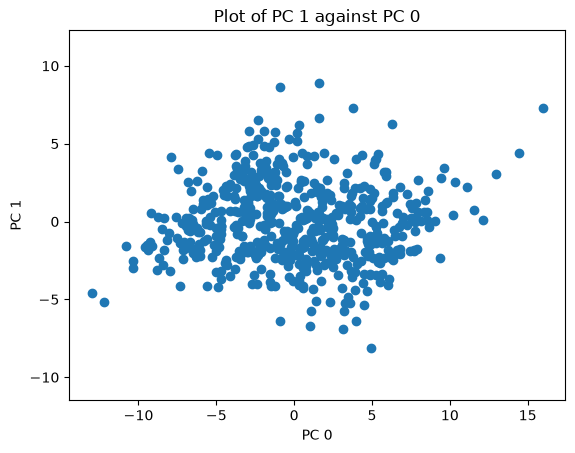

In [24]:
plt.scatter(x = finalPCA[0], y = finalPCA[1])
plt.title("Plot of PC 1 against PC 0")
plt.xlabel("PC 0")
plt.ylabel("PC 1")
plt.axis('equal')
plt.show()

Below is the ratio of explained variance by each PC

In [25]:
final_pca.explained_variance_ratio_
ratios = pd.DataFrame({'PC': finalPCA.columns, 'Ratio': final_pca.explained_variance_ratio_})
ratios.head()

,PC,Ratio
0,0,0.401601
1,1,0.125057
2,2,0.085163
3,3,0.080898
4,4,0.042338


We plot the scree plot to visualize the explained variance by each PC

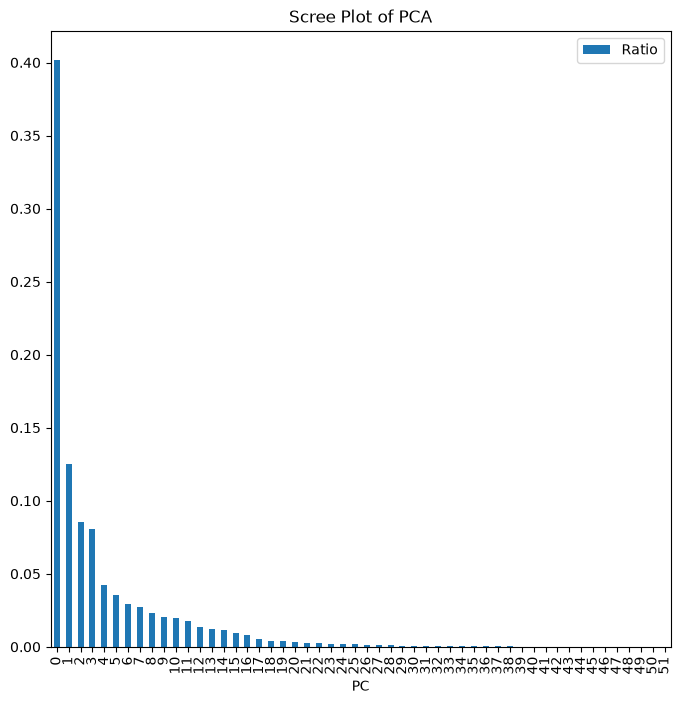

In [26]:
ratios.plot.bar(x = "PC", y = "Ratio", figsize = (8, 8))
plt.title("Scree Plot of PCA")
plt.show()

Below are the components of the PCA

In [27]:
final_pca.components_
comps = pd.DataFrame(final_pca.components_, index = finalPCA.columns, columns = final_norm.columns)
comps.iloc[0:5,:]

,player_age,ab,pa,hit,single,double,triple,strikeout,walk,k_percent,...,whiff_percent,swing_percent,pull_percent,straightaway_percent,opposite_percent,batted_ball,groundballs_percent,groundballs,linedrives_percent,linedrives
0,0.012890,0.196484,0.198107,0.200852,0.186854,0.194728,0.104201,0.181862,0.186151,-0.066821,...,-0.039925,-0.023726,0.010999,0.001318,-0.014521,0.191601,-0.067618,0.178217,0.052654,0.189756
1,-0.021154,-0.143924,-0.138723,-0.135995,-0.178897,-0.104533,-0.072992,-0.045937,-0.063939,0.209244,...,0.232838,-0.010657,0.091806,-0.062818,-0.051805,-0.169871,-0.104082,-0.192760,-0.004118,-0.170089
2,-0.009925,-0.105391,-0.103022,-0.057734,-0.028312,-0.071123,-0.025320,-0.183173,-0.068872,-0.197280,...,-0.189133,-0.120701,-0.151837,0.070670,0.116794,-0.075140,0.108352,-0.042398,0.204698,-0.044931
3,0.112191,-0.025737,-0.020067,-0.031050,-0.041152,-0.013171,-0.031303,-0.036294,0.017529,-0.045463,...,-0.104298,-0.078103,0.167532,-0.221582,0.005301,-0.020523,-0.392173,-0.091263,0.088643,-0.005208
4,0.165956,-0.009315,0.013477,-0.029369,-0.042085,-0.027387,-0.077839,-0.000809,0.206020,-0.069670,...,-0.098863,-0.441559,0.211604,-0.092844,-0.167620,-0.011628,0.129816,-0.001522,-0.206219,-0.042140


Before we try and cluster the players, we try to find the optimal amount of clusters using the elbow method

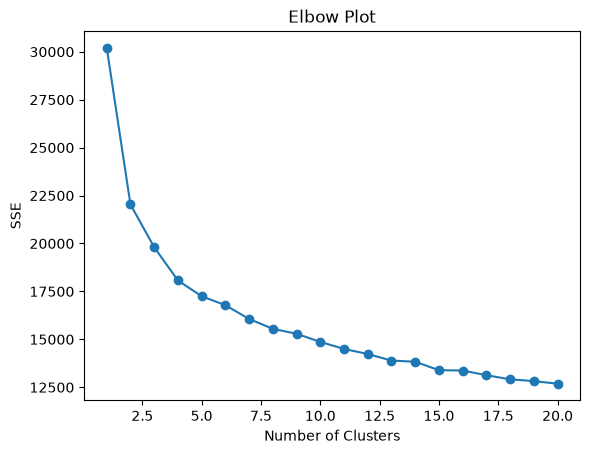

In [28]:
K = np.arange(1, 21)
Inertia = np.zeros(20)

for i in range(1, 21):
    km = sklearn.cluster.KMeans(n_clusters= i, n_init = 2, max_iter = 10, random_state = 2)
    km.fit_predict(finalPCA)
    Inertia[i-1] = km.inertia_

finalPCA_inertia = pd.DataFrame((K, Inertia)).transpose()
finalPCA_inertia = finalPCA_inertia.rename(columns = {0:"K", 1:"Inertia"})
finalPCA_inertia["K"]

plt.plot(finalPCA_inertia["K"], finalPCA_inertia["Inertia"])
plt.scatter(finalPCA_inertia["K"], finalPCA_inertia["Inertia"])
plt.xlabel("Number of Clusters")
plt.ylabel("SSE")
plt.title("Elbow Plot")
plt.show()

Looking at the plot, there doesn't seem to be a very distinct elbow point.

$k = 4$ seems to be the most suitable elbow point with the largest change in within cluster variance.

As such, we will fit the K Means using 4 clusters

In [29]:
km_PCA = sklearn.cluster.KMeans(n_clusters = 4, n_init = 2, max_iter = 10, random_state = 3)
km_labels = km_PCA.fit_predict(finalPCA)
km_labels_names = pd.DataFrame(km_labels, columns = ['Cluster'], index = final["player_name"])
km_labels_names

,Cluster
player_name,
"Duran, Jarren",0
"Ohtani, Shohei",0
"Henderson, Gunnar",0
"Semien, Marcus",0
"Soto, Juan",0
...,...
"Rios, Edwin",1
"Kemp, Tony",1
"Alcantara, Kevin",1


We now add the cluster labels to the original data

In [30]:
final_cluster = final.copy()
final_cluster['cluster'] = km_labels
final_cluster.head()

,"last_name, first_name",player_id,year,player_age,ab,pa,hit,single,double,triple,...,straightaway_percent,opposite_percent,batted_ball,groundballs_percent,groundballs,linedrives_percent,linedrives,handed,player_name,cluster
0,"Duran, Jarren",680776,2024,27,671,735,191,108,48,14,...,40.0,30.1,515,46.8,241,25.6,132,L,"Duran, Jarren",0
1,"Ohtani, Shohei",660271,2024,29,636,731,197,98,38,7,...,32.6,23.8,479,36.3,174,26.9,129,L,"Ohtani, Shohei",0
2,"Henderson, Gunnar",683002,2024,23,630,719,177,102,31,7,...,40.0,23.4,475,47.4,225,24.6,117,L,"Henderson, Gunnar",0
3,"Semien, Marcus",543760,2024,33,650,718,154,102,27,2,...,33.7,20.3,546,39.6,216,22.5,123,R,"Semien, Marcus",0
4,"Soto, Juan",665742,2024,25,576,713,166,90,31,4,...,35.8,21.9,461,44.7,206,22.8,105,L,"Soto, Juan",0


Now we will plot the clusters using the first 2 Principal Components on the X and Y axis

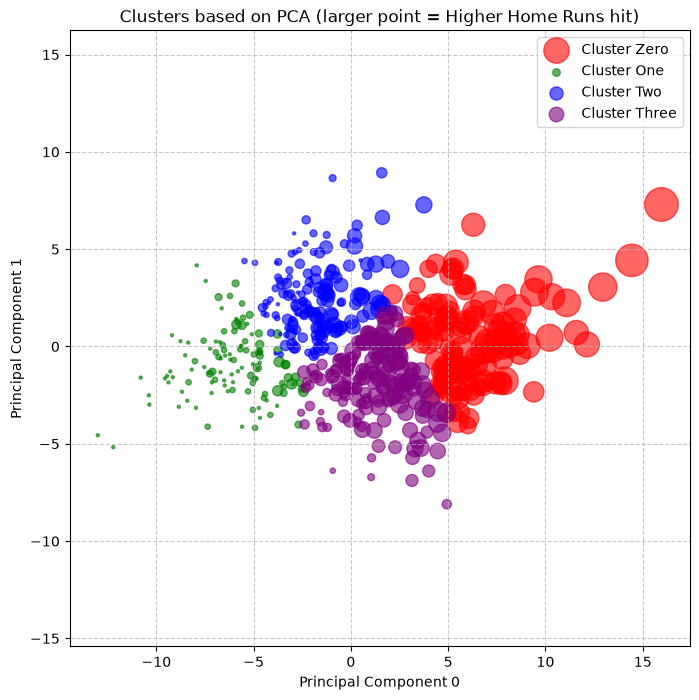

In [31]:
final_PCA_kmeans_labels = finalPCA.copy()
final_PCA_kmeans_labels['Cluster'] = km_labels
final_PCA_kmeans_labels

# Cluster labels added to PCA table
cluster_PCA_zero = final_PCA_kmeans_labels[final_PCA_kmeans_labels["Cluster"] == 0]
cluster_PCA_one = final_PCA_kmeans_labels[final_PCA_kmeans_labels["Cluster"] == 1]
cluster_PCA_two = final_PCA_kmeans_labels[final_PCA_kmeans_labels["Cluster"] == 2]
cluster_PCA_three = final_PCA_kmeans_labels[final_PCA_kmeans_labels["Cluster"] == 3]

# Cluster labels added to original table
cluster_zero = final_cluster[final_cluster["cluster"] == 0]
cluster_one = final_cluster[final_cluster["cluster"] == 1]
cluster_two = final_cluster[final_cluster["cluster"] == 2]
cluster_three = final_cluster[final_cluster["cluster"] == 3]


plt.figure(figsize=(8, 8))
plt.scatter(cluster_PCA_zero[0], cluster_PCA_zero[1], c = 'red', s = 5 + 10 * cluster_zero['home_run'], alpha = 0.6, label = "Cluster Zero")
plt.scatter(cluster_PCA_one[0], cluster_PCA_one[1], c = 'green', s = 5 + 10 * cluster_one['home_run'], alpha = 0.6, label = "Cluster One")
plt.scatter(cluster_PCA_two[0], cluster_PCA_two[1], c = 'blue', s = 5 + 10 * cluster_two['home_run'], alpha = 0.6, label = "Cluster Two")
plt.scatter(cluster_PCA_three[0], cluster_PCA_three[1], c = 'purple', s = 5 + 10 * cluster_three['home_run'], alpha = 0.6, label = "Cluster Three")
plt.title("Clusters based on PCA (larger point = Higher Home Runs hit)")
plt.xlabel("Principal Component 0")
plt.ylabel("Principal Component 1")
plt.grid(axis='both', linestyle='--', alpha=0.7)
plt.legend()
plt.axis('equal')
plt.show()

Now we will check the home run average and the distribution of home runs for the different clusters

In [32]:
print("Mean home run (Cluster Zero)",cluster_zero["home_run"].mean())
print("Mean home run (Cluster One)",cluster_one["home_run"].mean())
print("Mean home run (Cluster Two)",cluster_two["home_run"].mean())
print("Mean home run (Cluster Three)",cluster_three["home_run"].mean())

Mean home run (Cluster Zero) 22.828358208955223
Mean home run (Cluster One) 0.9310344827586207
Mean home run (Cluster Two) 4.578313253012048
Mean home run (Cluster Three) 9.096385542168674


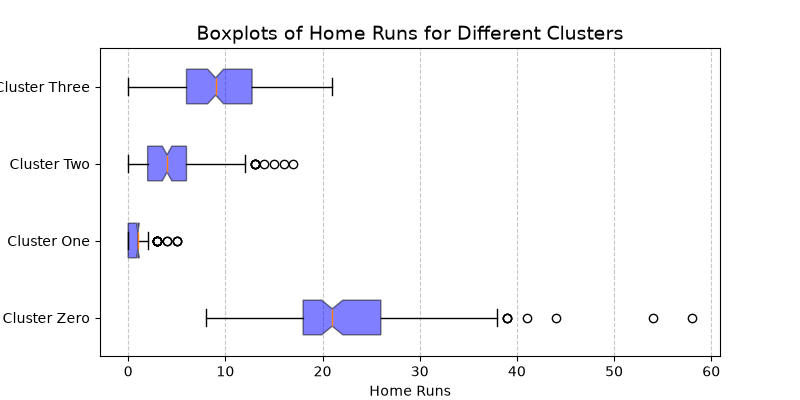

In [53]:
plt.figure(figsize = (8, 4))
plt.boxplot((cluster_zero["home_run"], cluster_one["home_run"], cluster_two["home_run"], cluster_three["home_run"]),tick_labels = ("Cluster Zero", "Cluster One", "Cluster Two", "Cluster Three"), orientation = 'horizontal', notch = True, patch_artist = True, boxprops = dict(facecolor = "b", alpha = 0.5))
plt.title("Boxplots of Home Runs for Different Clusters", fontsize = 14)
plt.xlabel("Home Runs")
plt.ylabel("Cluster")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

Looking at the mean home runs and boxplots for each cluster, it seems clear that Cluster One consists of players that hit more home runs

Now, we will look at the PCA components to see which statistics explain the likelihood of hitting a home run

More specifically, we will look at the first two PCA components

In [34]:
pca_one = pd.DataFrame(comps.iloc[0,:])
pca_one.sort_values(by = 0, key = abs, ascending=False).head()

,0
b_rbi,0.202384
hit,0.200852
pa,0.198107
pitch_count,0.198091
b_total_strike,0.196581


In [35]:
pca_two = pd.DataFrame(comps.iloc[1,:])
pca_two.sort_values(by = 1, key = abs, ascending=False).head()

,1
barrel_batted_rate,0.261035
avg_hyper_speed,0.253874
hard_hit_percent,0.240307
avg_swing_speed,0.236809
xiso,0.234731


Looking at the first five factors in the first and second Principal Components, it seems that the factors that explain the number of home runs hit are

For the first component:

* b_rbi
* hit
* pa
* pitch_count
* b_total_strike

For the second component:

* barrel_batted_rate
* avg_hyper_speed
* avg_swing_speed
* hard_hit_percent
* xiso

## DBSCAN

One concern we have after doing K Means is that there does not seem to be a very clear elbow point, furthermore when looking at the plot of the data there seem to be outliers that may be skewing the clusters. 

As such we will use the DBSCAN clustering method and see if it produces different results.

In [36]:
dbscan_final = sklearn.cluster.DBSCAN(eps = 1, min_samples = 3, metric = "l1")
dbscan_labels = dbscan_final.fit_predict(finalPCA.iloc[:,0:2])
dbscan_labels_df = pd.DataFrame(dbscan_labels, index = finalPCA.index, columns = ['Cluster'])

print("Clusters:", set(dbscan_labels))
dbscan_labels_df.head()


Clusters: {np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(-1)}


,Cluster
player_name,
"Duran, Jarren",-1
"Ohtani, Shohei",-1
"Henderson, Gunnar",-1
"Semien, Marcus",0
"Soto, Juan",-1


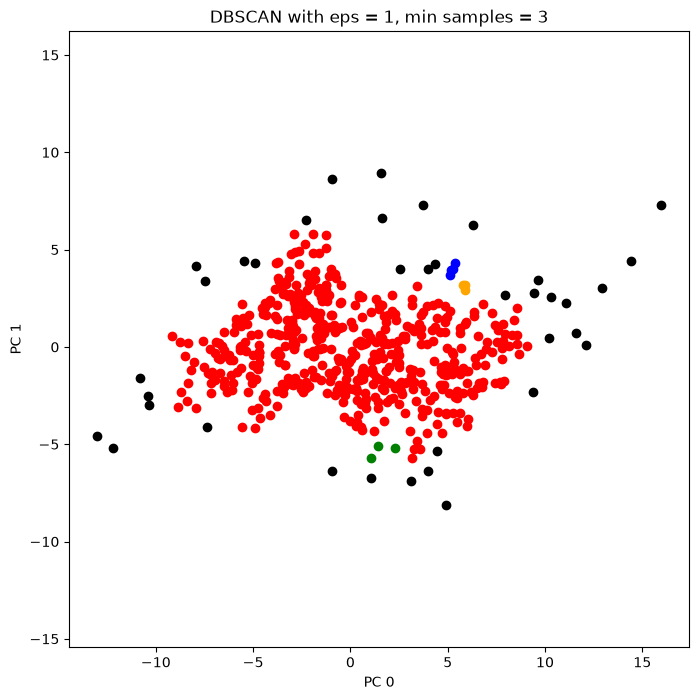

In [37]:
final_PCA_dbscan_labels = finalPCA.copy()
final_PCA_dbscan_labels['Cluster'] = dbscan_labels
final_PCA_dbscan_labels

cluster_dbscan_zero = final_PCA_dbscan_labels[final_PCA_dbscan_labels["Cluster"] == 0]
cluster_dbscan_one = final_PCA_dbscan_labels[final_PCA_dbscan_labels["Cluster"] == 1]
cluster_dbscan_two = final_PCA_dbscan_labels[final_PCA_dbscan_labels["Cluster"] == 2]
cluster_dbscan_three = final_PCA_dbscan_labels[final_PCA_dbscan_labels["Cluster"] == 3]
cluster_dbscan_outliers = final_PCA_dbscan_labels[final_PCA_dbscan_labels["Cluster"] == -1]

plt.figure(figsize=(8, 8))
plt.scatter(cluster_dbscan_zero[0], cluster_dbscan_zero[1], c = 'red')
plt.scatter(cluster_dbscan_one[0], cluster_dbscan_one[1], c = 'green')
plt.scatter(cluster_dbscan_two[0], cluster_dbscan_two[1], c = 'blue')
plt.scatter(cluster_dbscan_three[0], cluster_dbscan_three[1], c = 'orange')
plt.scatter(cluster_dbscan_outliers[0], cluster_dbscan_outliers[1], c = 'black')

plt.xlabel('PC 0')
plt.ylabel('PC 1')
plt.title('DBSCAN with eps = 1, min samples = 3')
plt.axis('equal')
plt.show()

In [38]:
final_dbscan = final.copy()
final_dbscan['Cluster'] = dbscan_labels
dbscan_cluster_zero_final = final_dbscan[final_dbscan["Cluster"] == 0]
print("Mean Home Runs Cluster Zero:", np.mean(dbscan_cluster_zero_final['home_run']))
print("Mean Home Runs Cluster One:", np.mean(final_dbscan[final_dbscan["Cluster"] == 1]['home_run']))
print("Mean Home Runs Cluster Two:", np.mean(final_dbscan[final_dbscan["Cluster"] == 2]['home_run']))
print("Mean Home Runs Cluster Three:", np.mean(final_dbscan[final_dbscan["Cluster"] == 3]['home_run']))

Mean Home Runs Cluster Zero: 8.994094488188976
Mean Home Runs Cluster One: 6.333333333333333
Mean Home Runs Cluster Two: 24.25
Mean Home Runs Cluster Three: 21.0


While the DBSCAN may not represent the league perfectly, it shows the disparity amongst batters even at the highest level. Most of the league is rather average when it comes to hitting homeruns, but a few players are standouts when it comes to hitting.

However, in terms of clustering the K Means results are superior.

# Classifying Batters

After looking at the K Means clusters, it seems that we can categorize batters into four groups

* Elite (Cluster One)
* Good (Cluster Two)
* Decent (Cluster Three)
* Below Average (Cluster Zero)

One new question we want to answer is whether we can classify batters into these 4 groups based on the 10 factors we found that explain home runs hit.

We will use the Random Forest Classification Model to classify batters

The Ten Stats we will use are

* b_rbi
* hit
* pa
* pitch_count
* b_total_strike
* barrel_batted_rate
* avg_hyper_speed
* avg_swing_speed
* hard_hit_percent
* xiso

In [39]:
import sklearn.model_selection

ten_stats = final[['b_rbi', 'hit', 'pa', 'pitch_count', 'b_total_strike', 'barrel_batted_rate', 'avg_hyper_speed', 'avg_swing_speed', 'hard_hit_percent', 'xiso']]
ten_norm = (ten_stats - ten_stats.mean())/ten_stats.std()

(ten_train, ten_test, cluster_train, cluster_test) = sklearn.model_selection.train_test_split(ten_norm, km_labels, test_size = 0.5, random_state = 32)

In [40]:
from sklearn.ensemble import RandomForestClassifier

batter_classifier = RandomForestClassifier(n_estimators=100, random_state=0xC3DA3654, max_depth= 3)
batter_classifier.fit(ten_train, cluster_train)
cluster_pred = batter_classifier.predict(ten_test)

Below is a visualization of a tree from the Random Forest model

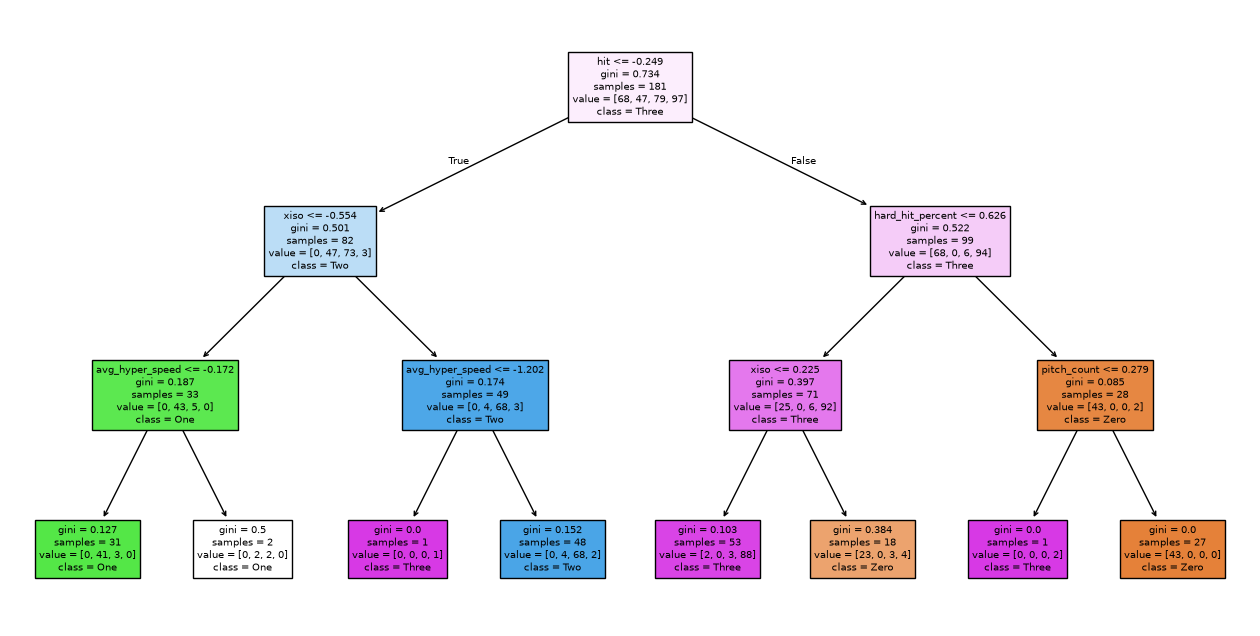

In [41]:
import sklearn.tree
batter_tree = batter_classifier.estimators_[0]
plt.figure(figsize = (16, 8))
plot = sklearn.tree.plot_tree(batter_tree, feature_names = batter_classifier.feature_names_in_, class_names = ['Zero', 'One', 'Two' ,'Three'], filled = True)
plt.show()

Below are the Feature Importances as a Barplot

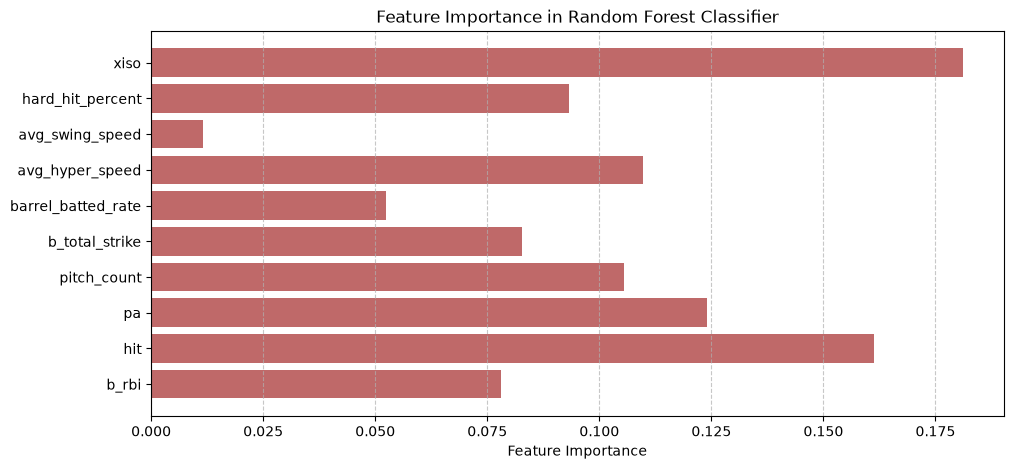

In [42]:
feature_importances = batter_classifier.feature_importances_

plt.figure(figsize = (11, 5))
plt.barh(ten_stats.columns, feature_importances, color = 'brown', alpha = 0.7)
plt.xlabel('Feature Importance')
plt.title('Feature Importance in Random Forest Classifier')
plt.grid(axis = 'x', linestyle = '--', alpha = 0.7)
plt.show()

Now we will analyze the results of our Random Forest Model

In [43]:
import sklearn.metrics

In [44]:
sklearn.metrics.confusion_matrix(cluster_test, cluster_pred, labels = batter_classifier.classes_)

array([[66,  0,  2,  3],
       [ 0, 48, 19,  1],
       [ 0,  5, 68,  1],
       [ 4,  2,  5, 67]])

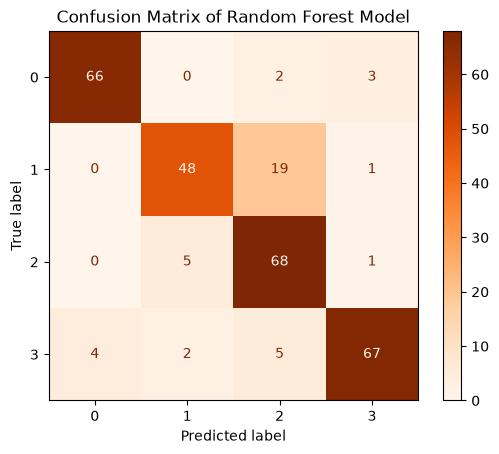

In [45]:
sklearn.metrics.ConfusionMatrixDisplay.from_predictions(cluster_test, cluster_pred, labels = batter_classifier.classes_, cmap = "Oranges")
plt.title("Confusion Matrix of Random Forest Model")
plt.show()

Looking at the Confusion Matrix, our Random Forest Model seems to be accurate and does not suffer from overfitting

In [46]:
print(sklearn.metrics.classification_report(cluster_test, cluster_pred))

              precision    recall  f1-score   support

           0       0.94      0.93      0.94        71
           1       0.87      0.71      0.78        68
           2       0.72      0.92      0.81        74
           3       0.93      0.86      0.89        78

    accuracy                           0.86       291
   macro avg       0.87      0.85      0.85       291
weighted avg       0.87      0.86      0.86       291



The Random Forest Model also seems to be accurate with an overall accuracy of 0.88

Now we will rerun the Random Forest with max_depth = 4 and max_depth = 5 to see if we get improved results

In [47]:
batter_classifier_four = RandomForestClassifier(n_estimators=100, random_state=0xC3DA3654, max_depth= 4)
batter_classifier_four.fit(ten_train, cluster_train)
cluster_pred_four = batter_classifier_four.predict(ten_test)

batter_classifier_five = RandomForestClassifier(n_estimators=100, random_state=0xC3DA3654, max_depth= 5)
batter_classifier_five.fit(ten_train, cluster_train)
cluster_pred_five = batter_classifier_five.predict(ten_test)

In [48]:
print("max_depth = 4")
print(sklearn.metrics.classification_report(cluster_test, cluster_pred_four))
print("\nmax_depth = 5")
print(sklearn.metrics.classification_report(cluster_test, cluster_pred_five))

max_depth = 4
              precision    recall  f1-score   support

           0       0.96      0.96      0.96        71
           1       0.85      0.69      0.76        68
           2       0.71      0.92      0.80        74
           3       0.96      0.85      0.90        78

    accuracy                           0.86       291
   macro avg       0.87      0.85      0.85       291
weighted avg       0.87      0.86      0.86       291


max_depth = 5
              precision    recall  f1-score   support

           0       0.94      0.96      0.95        71
           1       0.86      0.72      0.78        68
           2       0.73      0.92      0.81        74
           3       0.96      0.85      0.90        78

    accuracy                           0.86       291
   macro avg       0.87      0.86      0.86       291
weighted avg       0.87      0.86      0.86       291



Based on the results above, max_depth = 5 seems to be the depth with the most accuracy. 

However, there does not seem to be a significant difference in accuracy when increasing the max_depth. 

Now, since max_depth = 5 has the highest accuracy for this training split seed, we will use max_depth = 5 to plot the feature importances sorted by importance of the Random Forest Model to compare the feature importances

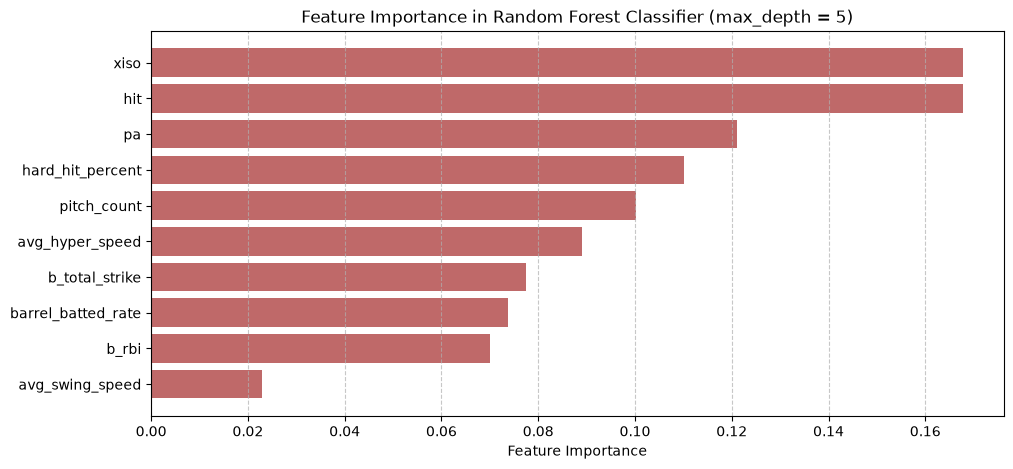

In [49]:
feature_importances_five = batter_classifier_five.feature_importances_
feature_importances_five_df = pd.DataFrame(feature_importances_five, index = ten_stats.columns)
sorted_five = feature_importances_five_df.sort_values(by = 0)

plt.figure(figsize = (11, 5))
plt.barh(sorted_five.index, sorted_five[0], color = 'brown', alpha = 0.7)
plt.xlabel('Feature Importance')
plt.title('Feature Importance in Random Forest Classifier (max_depth = 5)')
plt.grid(axis = 'x', linestyle = '--', alpha = 0.7)
plt.show()

Looking at the plot above, xiso, hit and pa appear to be the most important metrics when predicting likelihood of home runs. 

Below is a scatterplot of the original clusters found using K Means, with added interactivity of being able to click a point and see the following

* Player Name
* xiso
* hit
* pa
* Home Runs

In [50]:
import ipywidgets
from IPython.display import display

In [51]:
%matplotlib widget
#%matplotlib notebook
#%matplotlib inline

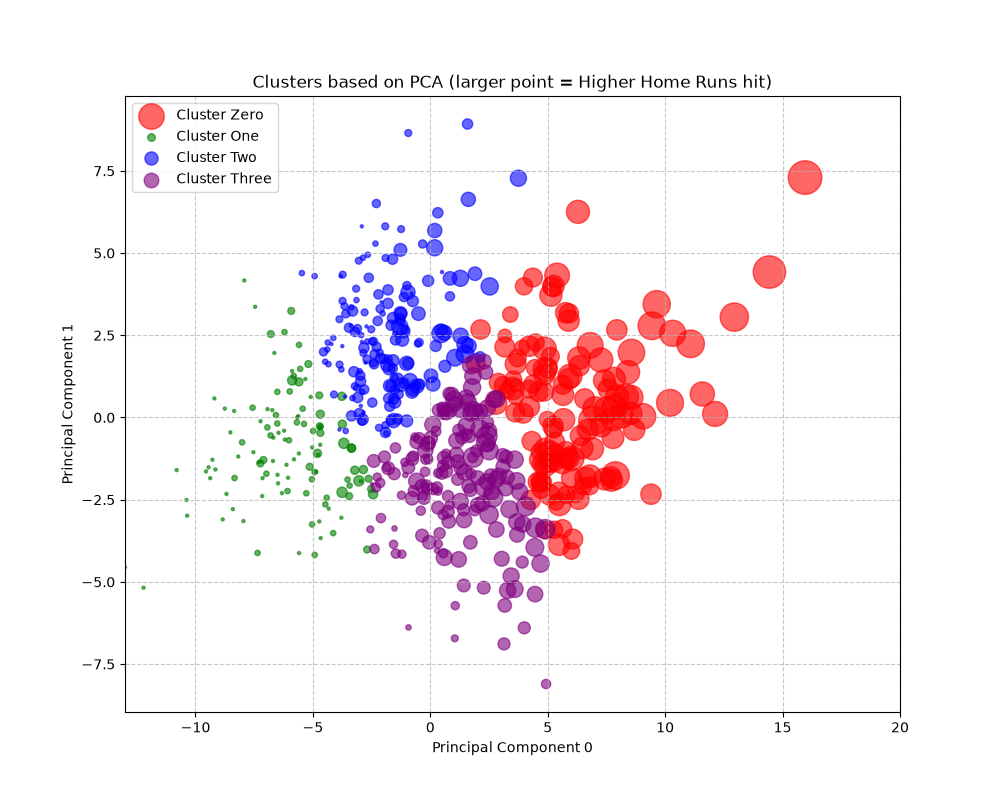

16

In [52]:
plt.figure(figsize = (10, 8))
s0 = plt.scatter(cluster_PCA_zero[0], cluster_PCA_zero[1], c = 'red', s = 5 + 10 * cluster_zero['home_run'], alpha = 0.6, label = "Cluster Zero", picker = True)
s1 = plt.scatter(cluster_PCA_one[0], cluster_PCA_one[1], c = 'green', s = 5 + 10 * cluster_one['home_run'], alpha = 0.6, label = "Cluster One", picker = True)
s2 = plt.scatter(cluster_PCA_two[0], cluster_PCA_two[1], c = 'blue', s = 5 + 10 * cluster_two['home_run'], alpha = 0.6, label = "Cluster Two", picker = True)
s3 = plt.scatter(cluster_PCA_three[0], cluster_PCA_three[1], c = 'purple', s = 5 + 10 * cluster_three['home_run'], alpha = 0.6, label = "Cluster Three", picker = True)
plt.title("Clusters based on PCA (larger point = Higher Home Runs hit)")
plt.xlabel("Principal Component 0")
plt.ylabel("Principal Component 1")
axis = plt.gca()
axis.set(xlim = (-13, 20))
plt.grid(axis='both', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

text = s0.figure.text(0.7, 0.3, "", wrap = True, color = 'brown', fontsize = 15)

def pick(event):
    artist = event.artist
    local_index = event.ind[0]

    if artist == s0:
        global_index = local_index
    elif artist == s1:
        global_index = len(cluster_zero) + local_index
    elif artist == s2:
        global_index = len(cluster_zero) + len(cluster_one) + local_index
    elif artist == s3:
        global_index = len(cluster_zero) + len(cluster_one) + len(cluster_two) + local_index

    info = pd.concat((cluster_zero, cluster_one, cluster_two, cluster_three)).iloc[global_index]
    text.set_text(info['player_name'] + "\n  xiso: " + str(info['xiso']) + "\n  hit: " + str(info['hit']) + "\n  pa: " + str(info['pa']) + "\n  Home Runs: " + str(info['home_run']))

s0.figure.canvas.mpl_connect('pick_event', pick)

## Conclusion

Our dataset contained 58 variables, many of which were deemed to be unimportant. We used many different methods of analysis to look at the relationships between the variables.

Methods included:
* SLR
* MLR
* MDS
* PCA
* K Means
* DBSCAN
* Random Forest Classification

These were our initial Research Questions: 
* What performance metrics are most strongly associated with hitting a home run in MLB hitters?
* How do number of barrels correlate with number of home runs hit by a hitter?
* Are younger or older hitters more likely to hit a home run?
* Are batters who bat left or right better at hitting home runs?

After our analysis of the questions our conclusions are as follows:
* In the original PCA we found that b_rbi, hits, pa, pitch_count, b_total_strike, barrel_batted_rate, avg_hyper_speed, avg_swing_speed, hard_hit_percent, and xiso were the 10 most important performance metrics for hitting a homerun.
* After further analysis, we determined that xiso, hits, and pa were the performance metrics most strongly associated with hitting a home run in the MLB.
* The $R^2$ value for barrels was 0.92, so it represents 92% of the variability in homeruns.
* Our multiple linear regression model resulted in a $R^2$ value of 0.94
* The distribution of home runs between younger and older hitters was similar, no statistically significant difference.
* Left and right handed players are relatively similar when it comes to batting, but switch hitters are more proficient with hitting home runs

Possible Follow Up Questions:
* Are certain hitting mechanics more commonly associated with hitters hitting a home run?
* How has the total number of home runs hit among MLB batters changed over time, and what factors may have contributed to any observed trends?
* Do switch hitters hit better from the left or right side of the plate?